# Tugas Praktikum 5: Sequential Pattern Analysis

**Nama:** Rayyan Muhtar Ali
**NRP:** 5054251051
**Mata Kuliah:** Penambangan Data

**Dataset:** Online Retail (UCI Machine Learning Repository), file `Online Retail.xlsx`, 541.909 baris dan 8 kolom.
Link: https://archive.ics.uci.edu/dataset/352/online+retail

Datanya berisi transaksi toko ritel online asal Inggris dari Desember 2010 sampai Desember 2011. Sebagian besar pelanggannya adalah grosir yang membeli barang hadiah dan dekorasi rumah. Pada tugas sebelumnya (association rule) yang dicari adalah barang yang dibeli **bersamaan** dalam satu keranjang. Di sini fokusnya beda: barang apa yang dibeli **lebih dulu** dan barang apa yang dibeli **di transaksi berikutnya** oleh pelanggan yang sama.

Alurnya: membersihkan data, menyusun setiap pelanggan menjadi satu sequence berisi itemset per invoice yang urut waktu, menjalankan algoritma **PrefixSpan**, lalu mengevaluasi pola yang ditemukan dengan support, confidence, dan lift.

## 1. Import dan Pemahaman Dataset

In [1]:
import time
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8, 4.5), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e3", "axes.axisbelow": True,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
})
BIRU, ORANYE, ABU = "#2a78d6", "#eb6834", "#a3a29c"
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 90)

In [2]:
# Dataset tidak diunggah ke repo, taruh Online Retail.xlsx di folder archive/ pada root repo
df_raw = pd.read_excel("../archive/Online Retail.xlsx")
df_raw.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
print("Shape:", df_raw.shape)
df_raw.info()

Shape: (541909, 8)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [4]:
df_raw[["Quantity", "UnitPrice"]].describe().round(2)

,Quantity,UnitPrice
count,541909.00,541909.00
mean,9.55,4.61
std,218.08,96.76
min,-80995.00,-11062.06
25%,1.00,1.25
50%,3.00,2.08
75%,10.00,4.13
max,80995.00,38970.00


In [5]:
print("Nilai kosong per kolom:")
print(df_raw.isna().sum())
print("\nRentang tanggal:", df_raw["InvoiceDate"].min(), "s.d.", df_raw["InvoiceDate"].max())

Nilai kosong per kolom:


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Rentang tanggal: 2010-12-01 08:26:00 s.d. 2011-12-09 12:50:00


Dataset punya 8 kolom: `InvoiceNo` (nomor invoice, diawali "C" kalau dibatalkan), `StockCode` dan `Description` (kode serta nama produk), `Quantity`, `InvoiceDate`, `UnitPrice` (harga satuan dalam pound sterling), `CustomerID`, dan `Country`. Ada 1.454 baris tanpa `Description` dan 135.080 baris (sekitar 25%) tanpa `CustomerID`. `Quantity` ada yang negatif sampai -80.995, dan `UnitPrice` ada yang negatif. Semua itu adalah retur, pembatalan, atau penyesuaian stok, jadi bukan pembelian.

## 2. Eksplorasi dan Pembersihan Data

Untuk analisis pola berurutan, kolom yang saya pakai:

- `CustomerID`: satu pelanggan menjadi satu sequence.
- `InvoiceDate` dan `InvoiceNo`: menentukan urutan transaksi dan batas satu itemset.
- `Description`: nama produk yang menjadi item. Saya pakai nama produk, bukan `StockCode`, supaya pola mudah dibaca.

Kolom `Quantity` dan `UnitPrice` hanya dipakai untuk menyaring baris yang tidak valid. Pembersihan dilakukan bertahap, dan setiap tahap dicatat jumlah baris, invoice, dan pelanggannya.

In [6]:
df = df_raw.copy()
df["InvoiceNo"] = df["InvoiceNo"].astype(str)
df["StockCode"] = df["StockCode"].astype(str)

log = []
def catat(tahap, d):
    log.append({"Tahap": tahap, "Baris": len(d),
                "Invoice": d["InvoiceNo"].nunique(),
                "Pelanggan": d["CustomerID"].nunique()})

catat("Data awal", df)
df = df.dropna(subset=["Description"]);              catat("Hapus Description kosong", df)
df = df[~df["InvoiceNo"].str.startswith("C")];       catat("Hapus invoice batal (C...)", df)
df = df[df["Quantity"] > 0];                         catat("Hapus Quantity <= 0", df)
df = df.dropna(subset=["CustomerID"]);               catat("Hapus CustomerID kosong", df)

Selain empat langkah wajib di atas, saya cek dulu `StockCode` yang bukan kode produk. Kode produk normal diawali 5 digit angka (misalnya `85123A`); sisanya adalah biaya ongkir, biaya bank, atau input manual.

In [7]:
non_produk = ~df["StockCode"].str.match(r"^\d{5}")
print(df[non_produk].groupby(["StockCode", "Description"]).size()
        .sort_values(ascending=False).to_string())
print("\nBaris dengan UnitPrice <= 0:", (df["UnitPrice"] <= 0).sum())

StockCode     Description               
POST          POSTAGE                       1099
M             Manual                         290
C2            CARRIAGE                       133
DOT           DOTCOM POSTAGE                  16
BANK CHARGES  Bank Charges                    12
PADS          PADS TO MATCH ALL CUSHIONS       4

Baris dengan UnitPrice <= 0: 40


`POSTAGE` (ongkos kirim) muncul di 1.099 baris, hampir di setiap invoice pelanggan luar negeri. Kalau dibiarkan, pola teratas akan dipenuhi `POSTAGE -> POSTAGE` yang tidak bermakna. Jadi baris non-produk ini saya buang, termasuk 40 baris berharga 0 (barang gratis atau penyesuaian). Spasi di awal dan akhir `Description` juga dirapikan.

In [8]:
df = df[~non_produk & (df["UnitPrice"] > 0)].copy()
df["Description"] = df["Description"].str.strip()
df["CustomerID"] = df["CustomerID"].astype(int)
catat("Hapus non-produk & harga 0", df)

ringkas = pd.DataFrame(log).set_index("Tahap")
ringkas["% baris tersisa"] = (ringkas["Baris"] / ringkas["Baris"].iloc[0] * 100).round(1)
ringkas

,Baris,Invoice,Pelanggan,% baris tersisa
Tahap,,,,
Data awal,541909,25900,4372,100.0
Hapus Description kosong,540455,24446,4372,99.7
Hapus invoice batal (C...),531167,20610,4339,98.0
Hapus Quantity <= 0,530693,20136,4339,97.9
Hapus CustomerID kosong,397924,18536,4339,73.4
Hapus non-produk & harga 0,396337,18402,4334,73.1


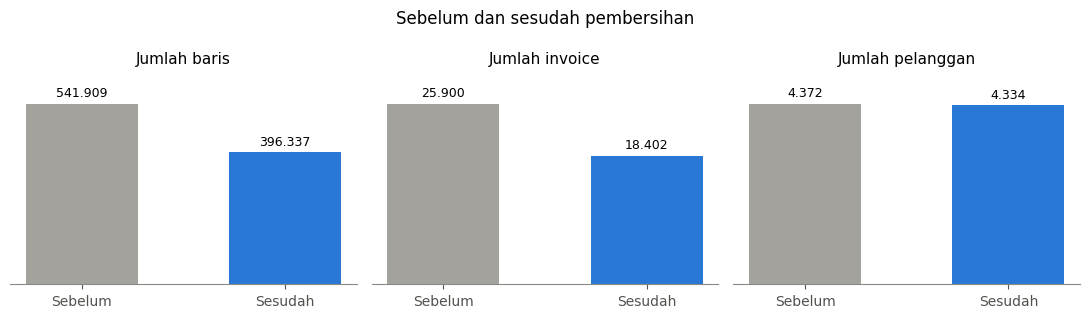

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, kol in zip(axes, ["Baris", "Invoice", "Pelanggan"]):
    nilai = [ringkas[kol].iloc[0], ringkas[kol].iloc[-1]]
    bar = ax.bar(["Sebelum", "Sesudah"], nilai, color=[ABU, BIRU], width=0.55)
    ax.bar_label(bar, labels=[f"{v:,}".replace(",", ".") for v in nilai], padding=3, fontsize=9)
    ax.set_title(f"Jumlah {kol.lower()}", fontsize=11)
    ax.set_yticks([]); ax.grid(False); ax.spines["left"].set_visible(False)
    ax.set_ylim(0, max(nilai) * 1.18)
fig.suptitle("Sebelum dan sesudah pembersihan", fontsize=12)
plt.tight_layout(); plt.show()

Dari 541.909 baris tersisa 396.337 baris (73,1%). Penurunan terbesar berasal dari `CustomerID` kosong, yang memang harus dibuang karena transaksi tanpa pelanggan tidak bisa dimasukkan ke sequence siapa pun. Jumlah invoice turun dari 25.900 menjadi 18.402. Ini karena pembatalan (sekitar 3.800 invoice) dan invoice tamu ikut terbuang. Pelanggan tersisa 4.334 dari 4.372. Pelanggan yang hilang adalah yang transaksinya hanya berisi pembatalan atau biaya non-produk.

Berikutnya saya lihat seberapa sering pelanggan kembali berbelanja, karena pola berurutan hanya bisa muncul dari pelanggan yang punya lebih dari satu invoice.

count    4334.00
mean        4.25
std         7.63
min         1.00
25%         1.00
50%         2.00
75%         5.00
max       206.00
Name: InvoiceNo, dtype: float64

Pelanggan dengan >= 2 invoice: 2829 (65.3%)


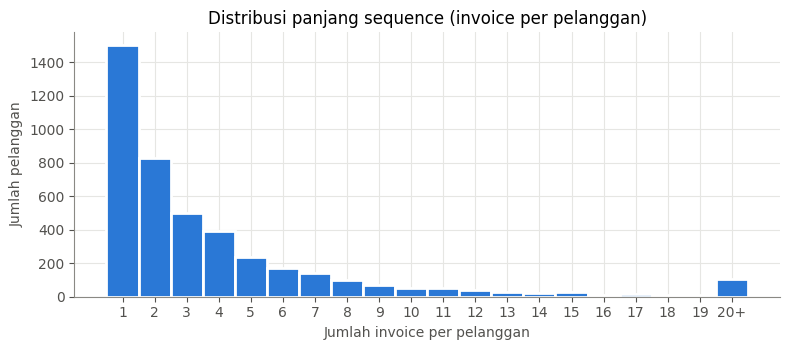

In [10]:
inv_per_cust = df.groupby("CustomerID")["InvoiceNo"].nunique()
print(inv_per_cust.describe().round(2))
print(f"\nPelanggan dengan >= 2 invoice: {(inv_per_cust >= 2).sum()} "
      f"({(inv_per_cust >= 2).mean():.1%})")

fig, ax = plt.subplots(figsize=(8, 3.6))
batas = inv_per_cust.clip(upper=20)
ax.hist(batas, bins=np.arange(0.5, 21.5, 1), color=BIRU, edgecolor="white", linewidth=2)
ax.set_xticks(range(1, 21)); ax.set_xticklabels([str(i) for i in range(1, 20)] + ["20+"])
ax.set_xlabel("Jumlah invoice per pelanggan"); ax.set_ylabel("Jumlah pelanggan")
ax.set_title("Distribusi panjang sequence (invoice per pelanggan)")
plt.tight_layout(); plt.show()

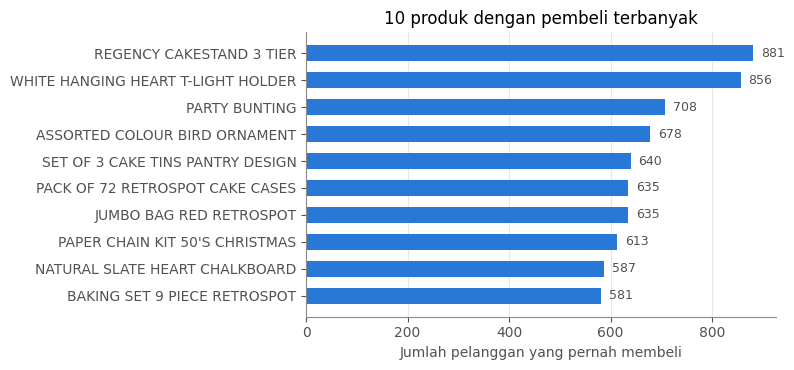

In [11]:
top_produk = df.groupby("Description")["CustomerID"].nunique().sort_values(ascending=False).head(10)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(top_produk.index[::-1], top_produk.values[::-1], color=BIRU, height=0.6)
for i, v in enumerate(top_produk.values[::-1]):
    ax.text(v + 15, i, str(v), va="center", fontsize=9, color="#52514e")
ax.set_xlabel("Jumlah pelanggan yang pernah membeli")
ax.set_title("10 produk dengan pembeli terbanyak")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

Median pelanggan hanya punya 2 invoice, dan sepertiga pelanggan (34,7%) cuma belanja sekali. Pelanggan seperti itu tetap dihitung di penyebut support, tapi tidak bisa menyumbang pola dengan dua langkah atau lebih. Di sisi lain ada pelanggan grosir dengan lebih dari 200 invoice. Produk dengan pembeli terbanyak adalah `REGENCY CAKESTAND 3 TIER` dan `WHITE HANGING HEART T-LIGHT HOLDER`, yang dibeli oleh 881 dan 856 pelanggan (sekitar 20% dari seluruh pelanggan).

## 3. Persiapan Data untuk Sequential Pattern Mining

Langkahnya:

1. Urutkan data berdasarkan `CustomerID` lalu `InvoiceDate`.
2. Kelompokkan baris per invoice menjadi satu **itemset**, yaitu himpunan produk unik di invoice itu. Kalau produk yang sama muncul dua kali di satu invoice, hanya dihitung sekali.
3. Kumpulkan itemset per pelanggan sesuai urutan waktu menjadi satu **sequence**.

Hasil akhirnya berupa list of list: `sequences[i]` adalah daftar itemset milik pelanggan ke-i.

In [12]:
df = df.sort_values(["CustomerID", "InvoiceDate", "InvoiceNo"])
# satu invoice = satu itemset; beberapa invoice tercatat di dua menit berbeda, jadi pakai waktu paling awal
invoice = (df.groupby(["CustomerID", "InvoiceNo"])
             .agg(InvoiceDate=("InvoiceDate", "min"),
                  Description=("Description", lambda x: sorted(set(x))))
             .reset_index().sort_values(["CustomerID", "InvoiceDate", "InvoiceNo"]))
seq_series = invoice.groupby("CustomerID")["Description"].agg(list)
sequences = seq_series.tolist()          # list of list of list (itemset)

print("Jumlah invoice (itemset):", len(invoice))
print("Jumlah sequence (pelanggan):", len(sequences))
print("Rata-rata itemset per sequence:", round(np.mean([len(s) for s in sequences]), 2))
print("Rata-rata item per itemset   :", round(invoice["Description"].map(len).mean(), 2))

Jumlah invoice (itemset): 18402
Jumlah sequence (pelanggan): 4334
Rata-rata itemset per sequence: 4.25
Rata-rata item per itemset   : 20.98


In [13]:
# Contoh: sequence milik pelanggan 12347 (hanya 3 itemset pertama, 4 item per itemset)
contoh = invoice[invoice["CustomerID"] == 12347].head(3)
for _, r in contoh.iterrows():
    print(r["InvoiceDate"].strftime("%Y-%m-%d"), r["InvoiceNo"],
          f"({len(r['Description'])} item):", r["Description"][:4], "...")

2010-12-07 537626 (31 item): ['3D DOG PICTURE PLAYING CARDS', 'AIRLINE BAG VINTAGE JET SET BROWN', 'ALARM CLOCK BAKELIKE CHOCOLATE', 'ALARM CLOCK BAKELIKE GREEN'] ...
2011-01-26 542237 (29 item): ['3D DOG PICTURE PLAYING CARDS', '60 TEATIME FAIRY CAKE CASES', '72 SWEETHEART FAIRY CAKE CASES', 'AIRLINE BAG VINTAGE JET SET BROWN'] ...
2011-04-07 549222 (24 item): ['3D SHEET OF CAT STICKERS', '3D SHEET OF DOG STICKERS', 'AIRLINE BAG VINTAGE JET SET BROWN', 'AIRLINE BAG VINTAGE JET SET RED'] ...


Supaya algoritma lebih cepat, nama produk dikodekan menjadi bilangan bulat dan setiap itemset disimpan sebagai tuple terurut. Daftar `items` dipakai untuk mengembalikan kode ke nama produk.

In [14]:
items = sorted({x for s in sequences for e in s for x in e})
kode = {x: i for i, x in enumerate(items)}
db = [[tuple(sorted(kode[x] for x in e)) for e in s] for s in sequences]
N = len(db)
print("Jumlah item unik:", len(items))
print("Contoh sequence terkode:", db[1][:2])

Jumlah item unik: 3860
Contoh sequence terkode: [(58, 126, 132, 133, 135, 136, 137, 273, 331, 344, 353, 389, 410, 499, 512, 577, 794, 810, 1105, 1281, 1465, 1825, 2033, 2403, 2439, 2615, 2663, 2673, 2742, 2974, 3090), (58, 99, 103, 126, 128, 132, 133, 135, 136, 137, 331, 438, 512, 715, 2031, 2253, 2255, 2490, 2712, 2713, 2742, 2750, 2892, 2974, 3086, 3236, 3401, 3430, 3756)]


## 4. Penerapan Algoritma PrefixSpan

**PrefixSpan** (Pei dkk., 2001) mencari pola berurutan dengan cara *pattern-growth*. Algoritma ini tidak membangkitkan kandidat seperti GSP. Mulai dari satu item yang frequent, database diproyeksikan menjadi bagian sequence yang muncul setelah prefix itu, lalu prefix diperpanjang dengan item yang masih frequent di database proyeksi. Ada dua cara memperpanjang prefix:

- **S-extension**: item baru ditaruh di itemset **berikutnya** (transaksi yang lebih belakang), misalnya `<{A}>` menjadi `<{A},{B}>`.
- **I-extension**: item baru masuk ke itemset **terakhir** yang sama (dibeli di invoice yang sama), misalnya `<{A}>` menjadi `<{A,B}>`.

Pustaka `prefixspan` di PyPI hanya mendukung sequence berisi item tunggal, sehingga tidak bisa membedakan "dibeli di invoice yang sama" dengan "dibeli di invoice berikutnya". Padahal data ini berupa sequence of itemset, dan SPMF butuh Java. Karena itu saya menulis implementasi PrefixSpan sendiri yang mendukung itemset. Untuk setiap prefix disimpan posisi itemset tempat prefix bisa berakhir di tiap sequence. Kumpulan posisi ini dipakai untuk menghitung kandidat I-extension (item lain di itemset yang sama) maupun S-extension (item di itemset setelah kemunculan pertama).

Support dihitung per pelanggan: satu pelanggan hanya dihitung sekali walaupun polanya muncul berulang di sequence-nya.

In [15]:
def prefixspan(db, min_count):
    """PrefixSpan untuk sequence of itemset.
    db        : list sequence, tiap sequence = list tuple item terurut (itemset)
    min_count : support minimum dalam jumlah sequence
    return    : dict {pola (tuple of tuple): jumlah sequence yang memuat pola}"""
    sets = [[frozenset(e) for e in s] for s in db]
    hasil = {}

    # pola panjang 1: item yang muncul di >= min_count sequence
    hitung = Counter(x for s in db for x in {y for e in s for y in e})
    stack = []
    for x, c in hitung.items():
        if c >= min_count:
            proj = [(sid, [j for j, e in enumerate(s) if x in e])
                    for sid, s in enumerate(sets)]
            stack.append((((x,),), [p for p in proj if p[1]]))

    while stack:
        pola, proj = stack.pop()       # proj: list (id sequence, posisi akhir pola)
        hasil[pola] = len(proj)
        akhir = pola[-1]
        i_cnt, s_cnt = defaultdict(int), defaultdict(int)
        for sid, pos in proj:
            s = db[sid]
            # I-extension: item > item terakhir, di itemset tempat pola berakhir
            for y in {y for j in pos for y in s[j] if y > akhir[-1]}:
                i_cnt[y] += 1
            # S-extension: item di itemset setelah kemunculan pertama
            for y in {y for e in s[pos[0] + 1:] for y in e}:
                s_cnt[y] += 1

        for y, c in i_cnt.items():
            if c >= min_count:
                baru = [(sid, [j for j in pos if y in sets[sid][j]]) for sid, pos in proj]
                stack.append((pola[:-1] + (akhir + (y,),), [p for p in baru if p[1]]))
        for y, c in s_cnt.items():
            if c >= min_count:
                baru = [(sid, [k for k in range(pos[0] + 1, len(sets[sid])) if y in sets[sid][k]])
                        for sid, pos in proj]
                stack.append((pola + ((y,),), [p for p in baru if p[1]]))
    return hasil

Sebelum dipakai ke data asli, implementasi ini saya uji dengan contoh dari buku Han & Kamber (dan paper PrefixSpan). Contohnya terdiri dari 4 sequence dengan `min_support = 2`, dan jawaban yang benar adalah **53 pola berurutan**, termasuk `<(ab)c>` dengan support 2.

In [16]:
toy = [[("a",), ("a","b","c"), ("a","c"), ("d",), ("c","f")],
       [("a","d"), ("c",), ("b","c"), ("a","e")],
       [("e","f"), ("a","b"), ("d","f"), ("c",), ("b",)],
       [("e",), ("g",), ("a","f"), ("c",), ("b",), ("c",)]]
hasil_toy = prefixspan(toy, 2)
print("Jumlah pola:", len(hasil_toy))
print("Support <(ab)c> :", hasil_toy.get((("a","b"), ("c",))))
print("Support <a(bc)a>:", hasil_toy.get((("a",), ("b","c"), ("a",))))

Jumlah pola: 53
Support <(ab)c> : 2
Support <a(bc)a>: 2


Hasilnya 53 pola, sama dengan buku, jadi implementasinya benar. Selanjutnya algoritma dijalankan pada data Online Retail. Sesuai instruksi, titik awalnya `min_support = 0.01` (relatif terhadap jumlah pelanggan). Sebagai perbandingan, saya jalankan juga beberapa nilai lain.

In [17]:
uji = []
hasil_per_minsup = {}
for ms in [0.05, 0.03, 0.02, 0.015, 0.01]:
    mc = int(np.ceil(ms * N))
    t0 = time.time()
    r = prefixspan(db, mc)
    dt = time.time() - t0
    hasil_per_minsup[ms] = r
    uji.append({"min_support": ms, "min_count (pelanggan)": mc, "jumlah pola": len(r),
                "pola >= 2 langkah": sum(len(p) >= 2 for p in r),
                "panjang item maks": max(sum(len(e) for e in p) for p in r),
                "waktu (detik)": round(dt, 1)})
uji = pd.DataFrame(uji).set_index("min_support")
uji

,min_count (pelanggan),jumlah pola,pola >= 2 langkah,panjang item maks,waktu (detik)
min_support,,,,,
0.050,217,305,9,3,5.1
0.030,131,1256,332,4,15.0
0.020,87,5170,2973,6,40.2
0.015,66,16675,12625,6,93.6
0.010,44,142218,131257,8,517.6


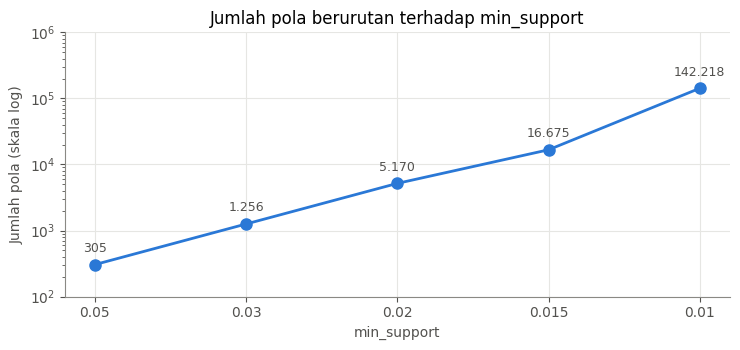

In [18]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
x = [str(v) for v in uji.index]
ax.plot(x, uji["jumlah pola"], marker="o", color=BIRU, linewidth=2, markersize=8)
ax.set_yscale("log")
for xi, v in zip(x, uji["jumlah pola"]):
    ax.annotate(f"{v:,}".replace(",", "."), (xi, v), textcoords="offset points",
                xytext=(0, 9), ha="center", fontsize=9, color="#52514e")
ax.set_xlabel("min_support"); ax.set_ylabel("Jumlah pola (skala log)")
ax.set_title("Jumlah pola berurutan terhadap min_support")
ax.set_ylim(100, 1e6)
plt.tight_layout(); plt.show()

**Penyesuaian minimum support.** Dengan `min_support = 0.01` (minimal 44 pelanggan), PrefixSpan menghasilkan lebih dari 140 ribu pola dalam waktu beberapa menit. Jumlah ini terlalu banyak untuk dianalisis, dan sebagian besar pola panjang hanyalah kombinasi ulang dari produk yang sama. Misalnya, satu pelanggan grosir yang rutin membeli puluhan jenis tas bisa memunculkan ribuan variasi urutan. Kenaikan jumlah polanya juga eksponensial: setiap kali min_support diturunkan sedikit, jumlah pola melonjak beberapa kali lipat.

Karena itu saya menaikkan nilainya menjadi **`min_support = 0.02`** (minimal 87 pelanggan). Pada nilai ini jumlah pola sekitar 5 ribu, sehingga masih bisa dibaca dan disaring. Setiap pola didukung oleh setidaknya 87 pelanggan berbeda, cukup kuat untuk dijadikan dasar keputusan bisnis. Pola dengan dua sampai empat langkah juga masih muncul. Sebaliknya, nilai 0.05 terlalu ketat karena hanya menyisakan segelintir pola multi-langkah, dan 0.03 hanya menangkap pola dari produk-produk terlaris saja.

## 5. Evaluasi Pola Berurutan

Untuk pola `P = <X1, X2, ..., Xk>` dengan k >= 2 itemset, metriknya:

- **Support(P)** = jumlah pelanggan yang sequence-nya memuat P dibagi jumlah seluruh pelanggan.
- **Confidence(P)** = Support(P) / Support(<X1, ..., Xk-1>). Artinya, dari pelanggan yang sudah melakukan langkah-langkah awal pola, berapa persen yang kemudian membeli `Xk` di transaksi **setelahnya**. Ini sama dengan confidence aturan `<X1..Xk-1>  =>  <Xk>`.
- **Lift(P)** = Confidence(P) / Support(<Xk>). Nilai lift di atas 1 berarti pembelian `Xk` lebih mungkin terjadi pada pelanggan yang sudah melewati prefix daripada pada pelanggan secara umum.

Pola yang hanya berisi satu itemset (misalnya `<{A,B}>`) tidak punya urutan waktu, jadi confidence-nya dibiarkan kosong.

In [19]:
MIN_SUP = 0.02
pola = hasil_per_minsup[MIN_SUP]

def teks(p):
    return "  ->  ".join("{" + ", ".join(items[i] for i in e) + "}" for e in p)

baris = []
for p, c in pola.items():
    sup = c / N
    if len(p) >= 2:
        conf = c / pola[p[:-1]]
        lift = conf / (pola[(p[-1],)] / N)
    else:
        conf = lift = np.nan
    baris.append({"pola": teks(p), "langkah": len(p), "jumlah_item": sum(len(e) for e in p),
                  "support_count": c, "support": sup, "confidence": conf, "lift": lift,
                  "ulang_produk_sama": len(p) >= 2 and len(set(p)) == 1, "_p": p})
hasil = pd.DataFrame(baris).sort_values("support", ascending=False).reset_index(drop=True)

print("Total pola frequent          :", len(hasil))
print(hasil["langkah"].value_counts().sort_index().rename("jumlah pola per banyak langkah").to_string())

Total pola frequent          : 5170
langkah
1    2197
2    2501
3     466
4       6


In [20]:
seq = hasil[hasil["langkah"] >= 2].reset_index(drop=True)
print("Pola berurutan (>= 2 langkah):", len(seq))
print("  - pembelian ulang produk sama:", seq["ulang_produk_sama"].sum())
print("  - melibatkan produk berbeda  :", (~seq["ulang_produk_sama"]).sum())
seq[["support", "confidence", "lift"]].describe().round(3)

Pola berurutan (>= 2 langkah): 2973
  - pembelian ulang produk sama: 186
  - melibatkan produk berbeda  : 2787


,support,confidence,lift
count,2973.000,2973.000,2973.000
mean,0.024,0.338,4.038
std,0.005,0.149,1.817
min,0.020,0.099,0.758
25%,0.021,0.219,2.635
50%,0.023,0.306,4.159
75%,0.026,0.452,5.192
max,0.093,0.826,10.835


Tabel berikut memuat 15 pola berurutan dengan support tertinggi.

In [21]:
kolom = ["pola", "support_count", "support", "confidence", "lift"]
seq[kolom].head(15).round(3)

,pola,support_count,support,confidence,lift
0,{WHITE HANGING HEART T-LIGHT HOLDER} -> {WHITE HANGING HEART T-LIGHT HOLDER},405,0.093,0.473,2.396
1,{REGENCY CAKESTAND 3 TIER} -> {REGENCY CAKESTAND 3 TIER},330,0.076,0.375,1.843
2,{JUMBO BAG RED RETROSPOT} -> {JUMBO BAG RED RETROSPOT},312,0.072,0.491,3.353
3,{ASSORTED COLOUR BIRD ORNAMENT} -> {ASSORTED COLOUR BIRD ORNAMENT},291,0.067,0.429,2.744
4,{PARTY BUNTING} -> {PARTY BUNTING},280,0.065,0.395,2.421
5,{LUNCH BAG RED RETROSPOT} -> {LUNCH BAG RED RETROSPOT},276,0.064,0.519,4.226
6,{LUNCH BAG BLACK SKULL.} -> {LUNCH BAG BLACK SKULL.},229,0.053,0.500,4.731
7,{SET OF 3 CAKE TINS PANTRY DESIGN} -> {SET OF 3 CAKE TINS PANTRY DESIGN},225,0.052,0.352,2.381
8,{WHITE HANGING HEART T-LIGHT HOLDER} -> {WHITE HANGING HEART T-LIGHT HOLDER} -> {W...,222,0.051,0.548,2.775
9,{LUNCH BAG RED RETROSPOT} -> {LUNCH BAG BLACK SKULL.},212,0.049,0.398,3.771


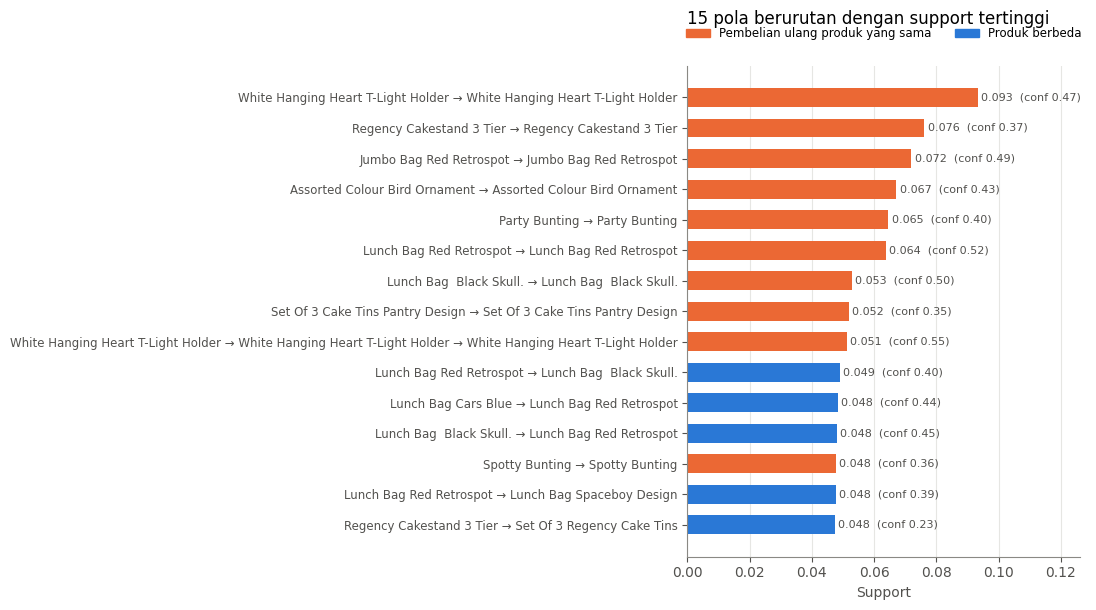

In [22]:
top = seq.head(15).iloc[::-1]
warna = [ORANYE if u else BIRU for u in top["ulang_produk_sama"]]
label = [t.replace("{", "").replace("}", "").replace("  ->  ", " → ").title() for t in top["pola"]]
fig, ax = plt.subplots(figsize=(11, 6.2))
ax.barh(range(len(top)), top["support"], color=warna, height=0.62)
ax.set_yticks(range(len(top)))
ax.set_yticklabels(label, fontsize=8.5)
for i, (s, c) in enumerate(zip(top["support"], top["confidence"])):
    ax.text(s + 0.001, i, f"{s:.3f}  (conf {c:.2f})", va="center", fontsize=8, color="#52514e")
ax.set_xlabel("Support"); ax.set_xlim(0, top["support"].max() * 1.35)
ax.grid(axis="y", visible=False)
ax.set_title("15 pola berurutan dengan support tertinggi", loc="left", pad=30)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=ORANYE, label="Pembelian ulang produk yang sama"),
                   Patch(color=BIRU, label="Produk berbeda")],
          loc="lower center", bbox_to_anchor=(0.5, 1.03), ncol=2, fontsize=8.5, frameon=False)
plt.tight_layout(); plt.show()

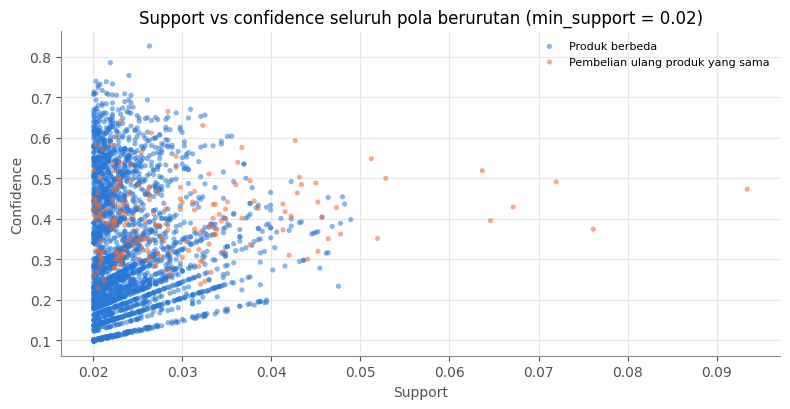

In [23]:
fig, ax = plt.subplots(figsize=(8, 4.2))
for ulang, w, lab in [(False, BIRU, "Produk berbeda"), (True, ORANYE, "Pembelian ulang produk yang sama")]:
    d = seq[seq["ulang_produk_sama"] == ulang]
    ax.scatter(d["support"], d["confidence"], s=14, color=w, alpha=0.55, label=lab, edgecolors="none")
ax.set_xlabel("Support"); ax.set_ylabel("Confidence")
ax.set_title("Support vs confidence seluruh pola berurutan (min_support = 0.02)")
ax.legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

Sebagian besar pola berurutan punya support di dekat batas bawah (0,02 sampai 0,03), sedangkan confidence-nya tersebar lebar dari sekitar 0,1 sampai di atas 0,8. Pola pembelian ulang produk yang sama (oranye) mendominasi support tertinggi. Pola dengan confidence tertinggi umumnya pola dua sampai tiga langkah dari satu keluarga produk, misalnya varian motif *jumbo bag*, *lunch bag*, atau *alarm clock bakelike*.

### Tiga pola terbaik berdasarkan support

In [24]:
top3 = seq.head(3)
top3[kolom].round(3)

,pola,support_count,support,confidence,lift
0,{WHITE HANGING HEART T-LIGHT HOLDER} -> {WHITE HANGING HEART T-LIGHT HOLDER},405,0.093,0.473,2.396
1,{REGENCY CAKESTAND 3 TIER} -> {REGENCY CAKESTAND 3 TIER},330,0.076,0.375,1.843
2,{JUMBO BAG RED RETROSPOT} -> {JUMBO BAG RED RETROSPOT},312,0.072,0.491,3.353



Tiga pola dengan support tertinggi semuanya berupa **pembelian ulang produk yang sama** di transaksi berikutnya:

1. **`<{WHITE HANGING HEART T-LIGHT HOLDER} -> {WHITE HANGING HEART T-LIGHT HOLDER}>`**: support 0,093, confidence 0,473, lift 2,40.
   Sebanyak 405 pelanggan (9,3%) membeli tempat lilin gantung hati putih ini, lalu membelinya lagi di invoice berikutnya. Dari 856 pelanggan yang pernah membelinya, 47% kembali membeli. Ini produk andalan toko. Karena pembelinya banyak yang grosir/pengecer, besar kemungkinan barang ini laku dijual kembali sehingga mereka perlu *restock*. Secara bisnis, stok produk ini harus selalu aman, dan pelanggan yang baru membelinya cocok dikirimi pengingat *reorder* atau penawaran volume.

2. **`<{REGENCY CAKESTAND 3 TIER} -> {REGENCY CAKESTAND 3 TIER}>`**: support 0,076, confidence 0,375, lift 1,84.
   Sebanyak 330 pelanggan membeli ulang cake stand 3 tingkat. Ini produk dengan pembeli terbanyak (881 pelanggan), tapi tingkat pembelian ulangnya (37,5%) lebih rendah daripada nomor 1 dan 3. Lift-nya juga paling kecil di antara ketiganya, karena produk ini memang sudah populer secara umum. Produk ini lebih cocok dijadikan "pintu masuk": pelanggan yang membelinya bisa diarahkan ke produk pelengkap dari seri Regency (lihat pola lintas produk di bawah).

3. **`<{JUMBO BAG RED RETROSPOT} -> {JUMBO BAG RED RETROSPOT}>`**: support 0,072, confidence 0,491, lift 3,35.
   Sebanyak 312 pelanggan membeli ulang tas jumbo motif polkadot merah. Hampir separuh pembelinya (49%) kembali membeli, dan lift 3,35 menunjukkan pembelian ulang ini jauh lebih sering daripada rata-rata. Tas belanja termasuk barang habis pakai, jadi pantas dijual dalam paket isi ulang atau dengan program langganan.

Ketiga pola ini menunjukkan bahwa pola berurutan paling kuat di toko ini adalah **loyalitas terhadap produk tertentu (repeat purchase)**, bukan perpindahan ke produk lain.


### Pola lintas produk dan pola dengan confidence tertinggi

Karena tiga besar seluruhnya pembelian ulang, saya juga menampilkan pola teratas yang melibatkan **produk berbeda**. Pola seperti ini lebih berguna untuk rekomendasi produk berikutnya (*next-product recommendation*).

In [25]:
lintas = seq[~seq["ulang_produk_sama"]]
lintas[kolom].head(10).round(3)

,pola,support_count,support,confidence,lift
9,{LUNCH BAG RED RETROSPOT} -> {LUNCH BAG BLACK SKULL.},212,0.049,0.398,3.771
10,{LUNCH BAG CARS BLUE} -> {LUNCH BAG RED RETROSPOT},209,0.048,0.436,3.555
11,{LUNCH BAG BLACK SKULL.} -> {LUNCH BAG RED RETROSPOT},208,0.048,0.454,3.700
13,{LUNCH BAG RED RETROSPOT} -> {LUNCH BAG SPACEBOY DESIGN},207,0.048,0.389,3.442
14,{REGENCY CAKESTAND 3 TIER} -> {SET OF 3 REGENCY CAKE TINS},206,0.048,0.234,2.147
16,{LUNCH BAG RED RETROSPOT} -> {LUNCH BAG SUKI DESIGN},203,0.047,0.382,4.145
17,{JUMBO BAG RED RETROSPOT} -> {JUMBO BAG VINTAGE DOILY},201,0.046,0.317,3.779
18,{LUNCH BAG PINK POLKADOT} -> {LUNCH BAG RED RETROSPOT},201,0.046,0.453,3.688
20,{JUMBO BAG RED RETROSPOT} -> {LUNCH BAG RED RETROSPOT},200,0.046,0.315,2.566
22,{LUNCH BAG SPACEBOY DESIGN} -> {LUNCH BAG RED RETROSPOT},198,0.046,0.404,3.292


Pola lintas produk teratas didominasi keluarga **Lunch Bag** dan **Jumbo Bag**. Contohnya, `<{LUNCH BAG RED RETROSPOT} -> {LUNCH BAG BLACK SKULL.}>` (support 0,049, confidence 0,398, lift 3,77): hampir 40% pembeli lunch bag motif polkadot merah kemudian membeli varian motif tengkorak hitam, dan arah sebaliknya juga kuat (confidence 0,454). Artinya, pelanggan yang cocok dengan satu model tas cenderung **mencoba motif lain dari lini yang sama** di pembelian berikutnya. Pola `<{REGENCY CAKESTAND 3 TIER} -> {SET OF 3 REGENCY CAKE TINS}>` (lift 2,15) juga menarik karena merupakan *cross-sell* dalam satu seri koleksi (Regency), dari cake stand ke kaleng kue.

In [26]:
# Pola dengan confidence tertinggi (support tetap >= 0.02)
seq.sort_values("confidence", ascending=False)[kolom + ["langkah"]].head(8).round(3)

,pola,support_count,support,confidence,lift,langkah
674,{JUMBO BAG RED RETROSPOT} -> {JUMBO BAG DOILEY PATTERNS} -> {JUMBO BAG RED RETROSPOT},114,0.026,0.826,5.638,3
1841,"{JUMBO BAG DOILEY PATTERNS, JUMBO BAG RED RETROSPOT} -> {JUMBO BAG RED RETROSPOT}",95,0.022,0.785,5.359,2
1141,{JUMBO BAG RED RETROSPOT} -> {JUMBO BAG DOILEY PATTERNS} -> {JUMBO BAG VINTAGE DOILY},104,0.024,0.754,8.998,3
2665,"{LUNCH BAG DOILEY PATTERN, LUNCH BAG RED RETROSPOT} -> {LUNCH BAG RED RETROSPOT}",88,0.020,0.739,6.024,2
2036,"{LUNCH BAG BLACK SKULL.} -> {LUNCH BAG PINK POLKADOT, LUNCH BAG RED RETROSPOT} -> ...",93,0.021,0.738,6.985,3
1692,{LUNCH BAG RED RETROSPOT} -> {LUNCH BAG DOILEY PATTERN} -> {LUNCH BAG RED RETROSPOT},96,0.022,0.733,5.970,3
2336,"{ALARM CLOCK BAKELIKE GREEN, ALARM CLOCK BAKELIKE ORANGE} -> {ALARM CLOCK BAKELIKE RED}",90,0.021,0.732,8.173,2
2557,"{JUMBO BAG RED RETROSPOT, JUMBO STORAGE BAG SUKI} -> {JUMBO BAG RED RETROSPOT} -> ...",89,0.021,0.730,4.979,3


Kalau diurutkan berdasarkan confidence, hasilnya berbeda. Pola `<{JUMBO BAG RED RETROSPOT} -> {JUMBO BAG DOILEY PATTERNS} -> {JUMBO BAG RED RETROSPOT}>` punya confidence 0,826: 83% pelanggan yang sudah membeli tas merah lalu tas motif doily akan kembali membeli tas merah. Pola `<{ALARM CLOCK BAKELIKE GREEN, ALARM CLOCK BAKELIKE ORANGE} -> {ALARM CLOCK BAKELIKE RED}>` (confidence 0,732, lift 8,17) menunjukkan pelanggan yang membeli dua warna jam weker biasanya melengkapi koleksinya dengan warna merah di transaksi berikutnya. Support pola-pola ini lebih kecil (sekitar 2%), tapi confidence dan lift-nya tinggi, sehingga cocok sebagai dasar rekomendasi yang tertarget.


## 6. Kesimpulan

**Hasil pembersihan data.** Dari 541.909 baris awal, setelah membuang Description kosong, invoice batal, Quantity <= 0, CustomerID kosong, serta baris non-produk (ongkir, biaya bank, input manual) dan harga 0, tersisa 396.337 baris (73,1%), 18.402 invoice, dan 4.334 pelanggan. Data ini disusun menjadi 4.334 sequence dengan rata-rata 4,25 itemset per pelanggan dan sekitar 21 produk per itemset. Sepertiga pelanggan hanya belanja sekali, sehingga pola berurutan sebenarnya berasal dari sekitar 2.829 pelanggan yang belanja lebih dari sekali.

**Penerapan algoritma.** PrefixSpan diimplementasikan sendiri agar mendukung sequence of itemset, lalu divalidasi dengan contoh buku (53 pola, sesuai). Dengan min_support awal 0,01, pola yang dihasilkan lebih dari 142 ribu sehingga tidak bisa dianalisis. Min_support kemudian dinaikkan ke **0,02** (minimal 87 pelanggan) dan menghasilkan 5.170 pola frequent, 2.973 di antaranya pola berurutan dengan dua langkah atau lebih.

**Pola yang ditemukan.**

- Tiga pola dengan support tertinggi adalah **pembelian ulang** *White Hanging Heart T-Light Holder* (support 0,093), *Regency Cakestand 3 Tier* (0,076), dan *Jumbo Bag Red Retrospot* (0,072). Confidence-nya 0,37 sampai 0,49, artinya sekitar 4 dari 10 pembeli produk tersebut kembali membeli produk yang sama. Pola paling dominan di toko ini adalah *restock* produk laris oleh pelanggan grosir.
- Pola lintas produk didominasi perpindahan **antar-motif dalam satu lini produk** (Lunch Bag, Jumbo Bag, Alarm Clock Bakelike, seri Regency), dengan lift umumnya di atas 2. Pelanggan jarang berpindah ke kategori yang jauh berbeda. Mereka lebih sering melengkapi koleksi dari lini yang sudah dibeli.
- Hampir semua pola (sekitar 99%) punya lift > 1 dengan median 4,2, jadi urutan pembelian ini bukan kebetulan dari popularitas produk saja.

**Implikasi bisnis.** (1) Jaga stok produk dengan tingkat pembelian ulang tinggi dan kirim pengingat *reorder* kepada pembelinya. (2) Setelah pelanggan membeli satu varian tas atau jam, rekomendasikan varian motif/warna lain dari lini yang sama pada kunjungan berikutnya. (3) Gunakan produk populer seperti Regency Cakestand sebagai pintu masuk untuk *cross-sell* produk satu koleksi.

**Keterbatasan.** Support dihitung per pelanggan tanpa memperhatikan jarak waktu antar-transaksi, sehingga pola "A lalu B" bisa saja berjarak berbulan-bulan. Selain itu, pelanggan grosir dengan ratusan invoice berkontribusi pada sangat banyak pola panjang. Analisis berikutnya bisa menambahkan batasan *max gap* waktu atau memisahkan pelanggan grosir dan eceran.
